In [1]:
import os
os.environ['HDF5_USE_FILE_LOCKING'] = 'FALSE'

from collections import defaultdict
from functools import lru_cache
from pathlib import Path
import random
from typing import Literal, get_args

import h5py
from hist import Hist
import matplotlib.pyplot as plt
import pandas as pd
import numba as nb
import numpy as np
from tqdm import tqdm

from h5flow.data import H5FlowDataManager

In [2]:
os.chdir('/pscratch/sd/m/mkramer/test/larnd-sim.segFFE3')

In [13]:
f_out = h5py.File('output/chg_inject/parallel_mip.LARND.hdf5')

In [15]:
pkts = f_out['packets'][:]
pkts[pkts['packet_type'] == 0]

array([(2, 20,  20, 0, 0, 1, 1, 11, 322489, 43, 0, 0, 0,  75, 238, 0, 0, 0, 0, 0, 1, 322489),
       (2, 20,  20, 0, 0, 0, 1,  5, 322487, 42, 0, 0, 0, 197, 237, 0, 0, 0, 0, 0, 1, 322487),
       (2, 20,  20, 0, 0, 1, 1,  4, 322486, 45, 0, 0, 0, 132, 237, 0, 0, 0, 0, 0, 1, 322486),
       (1, 20, 170, 0, 0, 0, 1, 27, 322488, 44, 0, 0, 0,  27, 238, 0, 0, 0, 0, 0, 1, 322488),
       (1, 20, 170, 0, 0, 1, 1, 26, 322489, 43, 0, 0, 0,  90, 238, 0, 0, 0, 0, 0, 1, 322489),
       (1, 20, 170, 0, 0, 1, 1, 21, 322489, 40, 0, 0, 0,  85, 238, 0, 0, 0, 0, 0, 1, 322489)],
      dtype=[('io_group', 'u1'), ('io_channel', 'u1'), ('chip_id', 'u1'), ('packet_type', 'u1'), ('downstream_marker', 'u1'), ('parity', 'u1'), ('valid_parity', 'u1'), ('channel_id', 'u1'), ('timestamp', '<u8'), ('dataword', 'u1'), ('trigger_type', 'u1'), ('local_fifo', 'u1'), ('shared_fifo', 'u1'), ('register_address', 'u1'), ('register_data', 'u1'), ('direction', 'u1'), ('local_fifo_events', 'u1'), ('shared_fifo_events', '<u2'), 

In [16]:
f_sig = np.load('output/chg_inject/parallel_mip.LARND.hdf5_signals/nf_signals.00.1.npz')

In [17]:
s = f_sig['signals_near']
p = f_sig['pixels_near']

In [18]:
s.shape

(144, 207)

In [19]:
max_amp = np.max(s, axis=1)
order = np.argsort(max_amp)[::-1]

/tmp/ipykernel_587849/428224725.py:2: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  plt.figure()


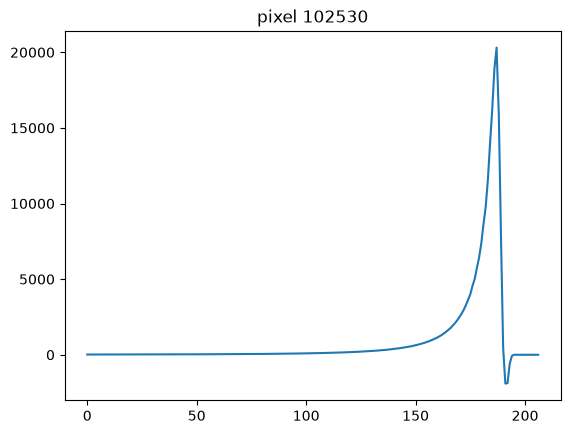

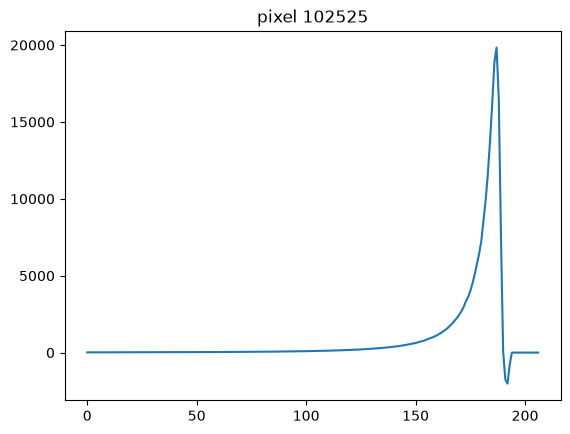

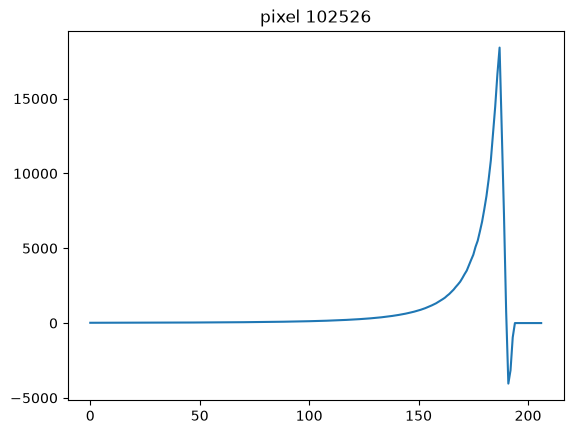

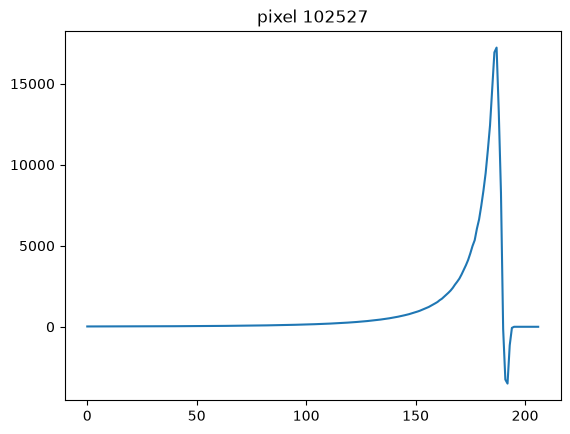

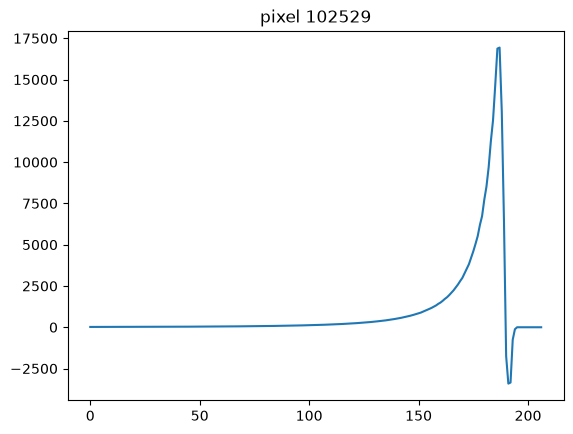

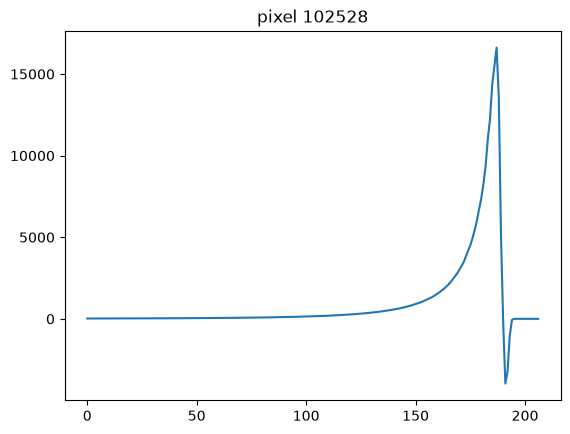

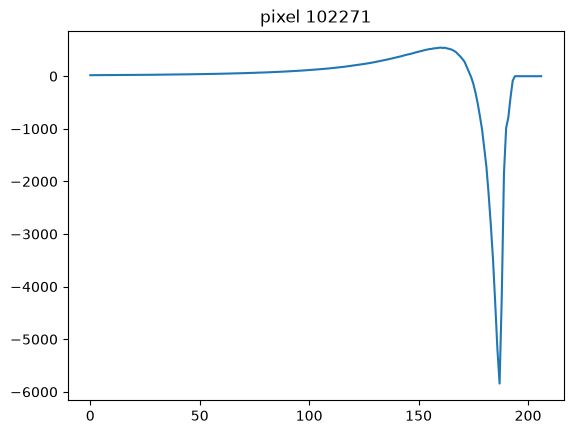

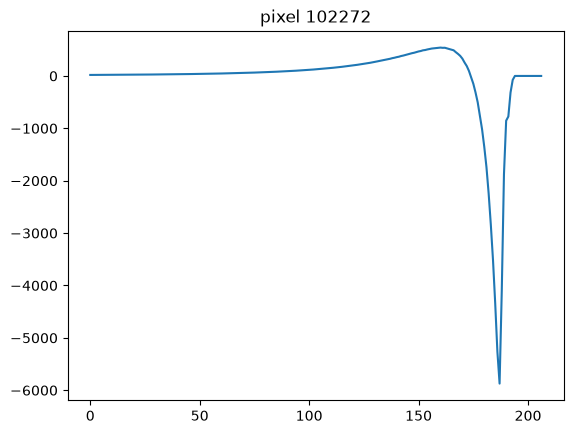

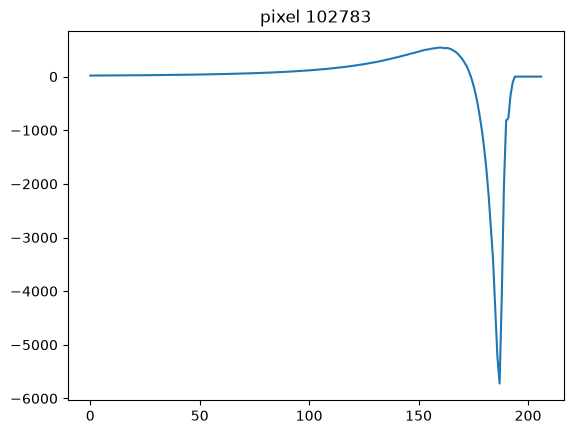

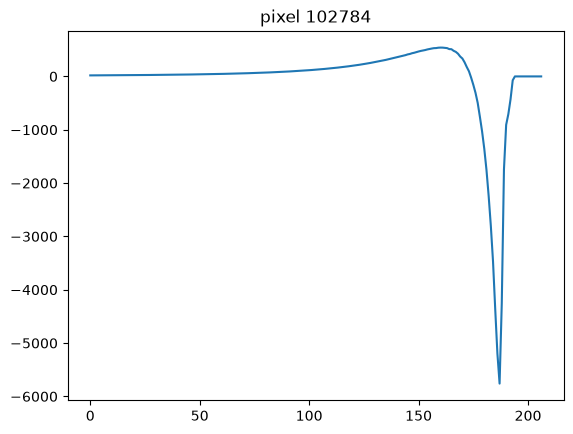

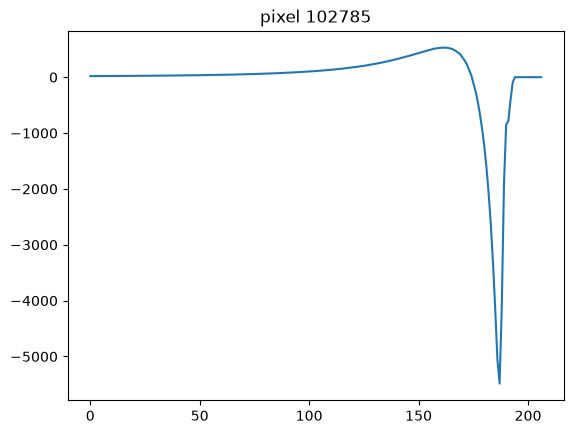

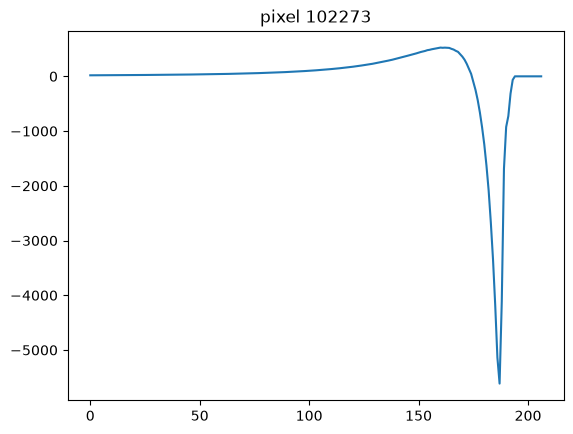

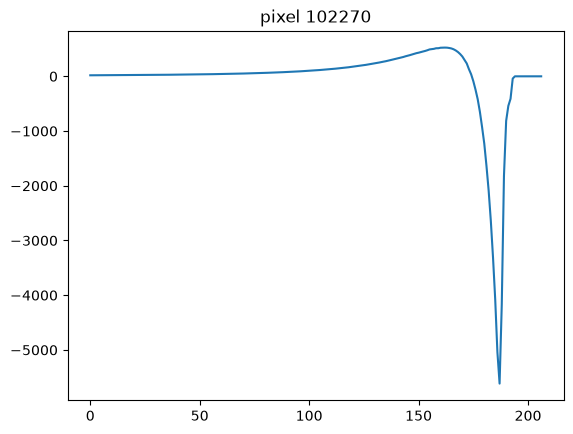

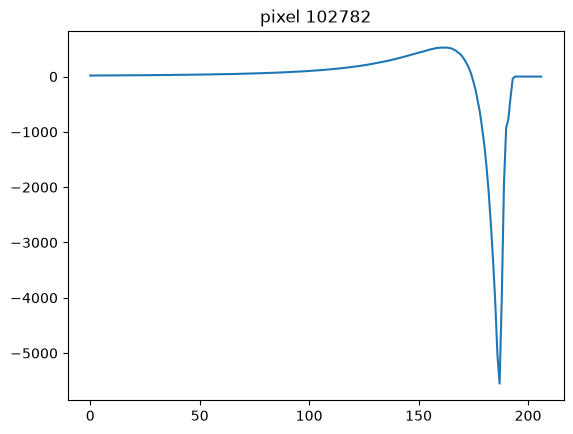

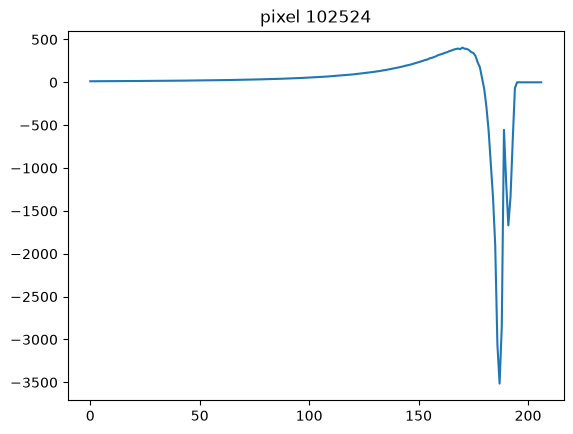

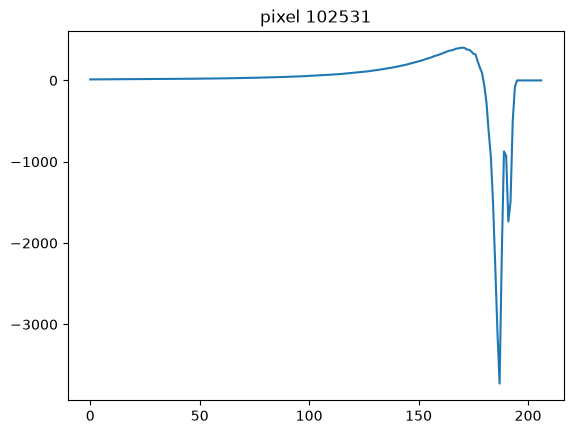

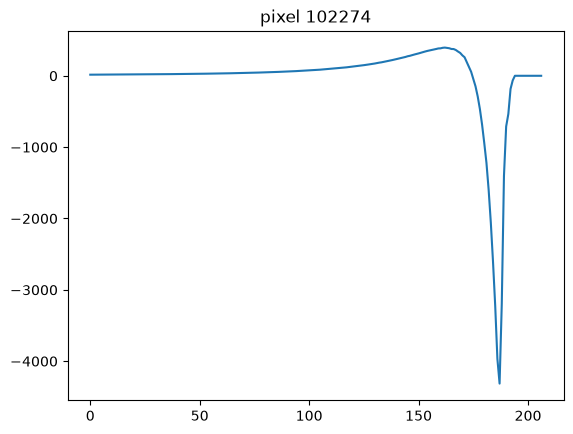

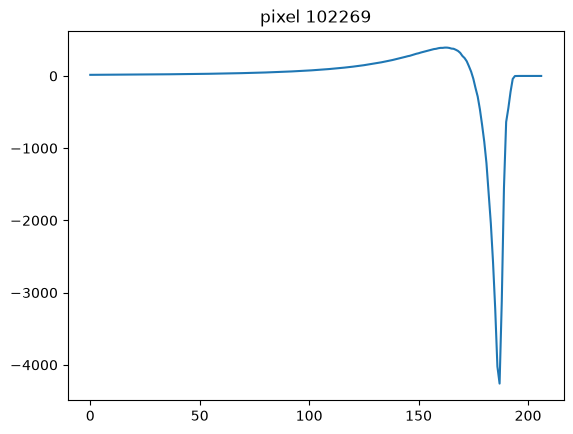

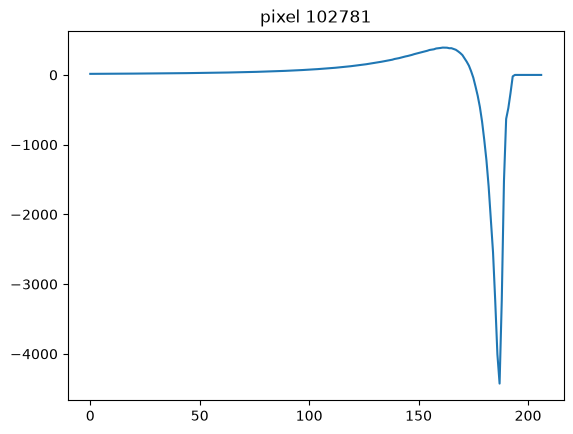

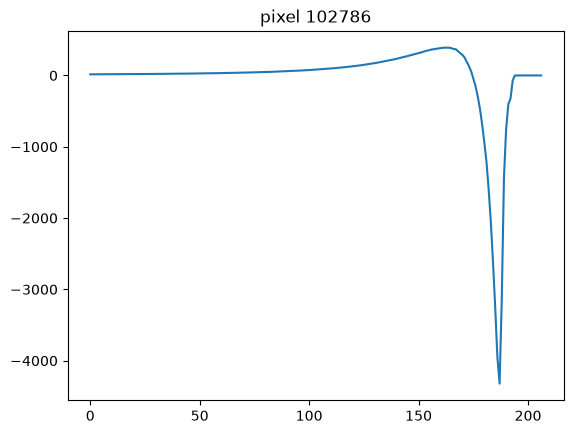

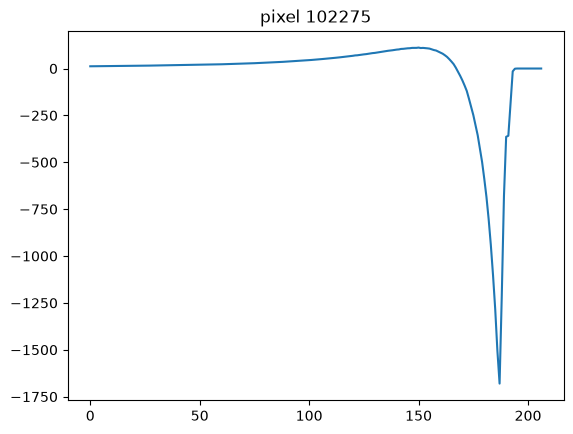

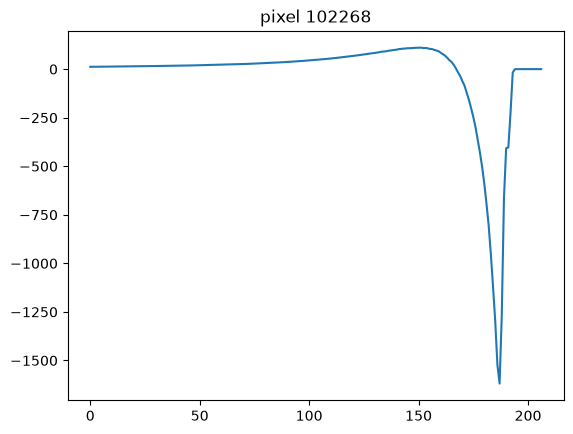

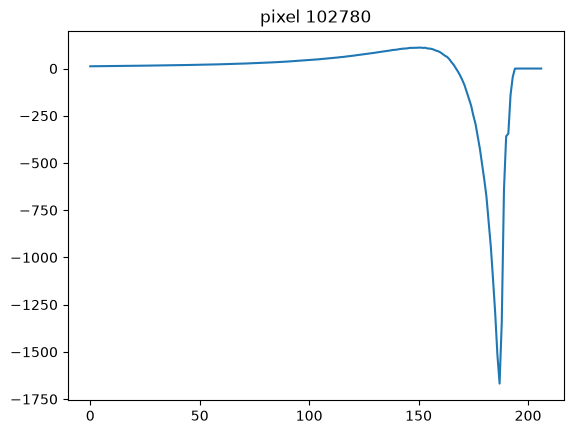

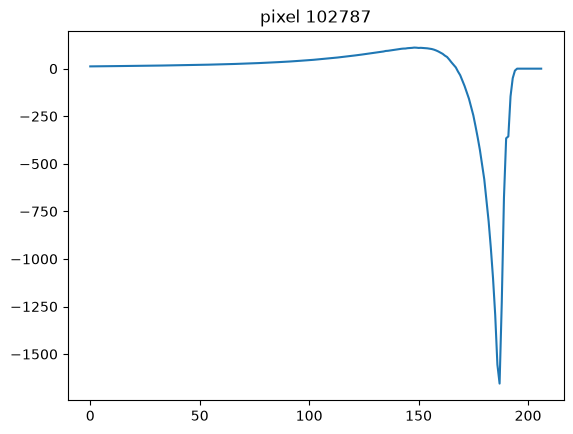

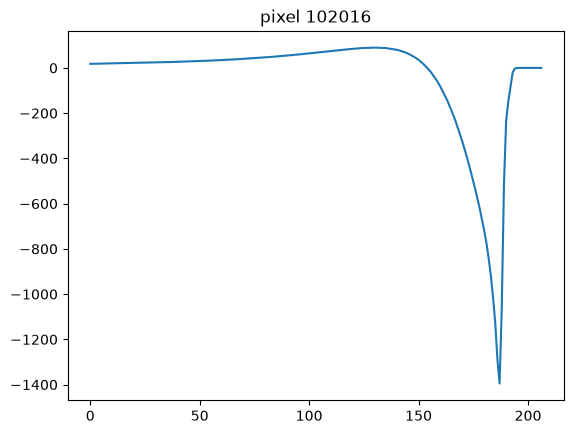

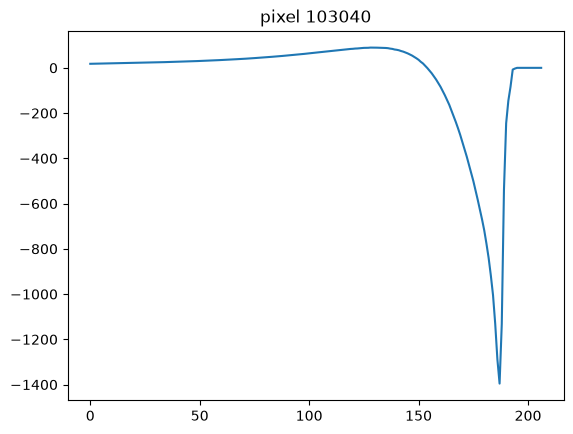

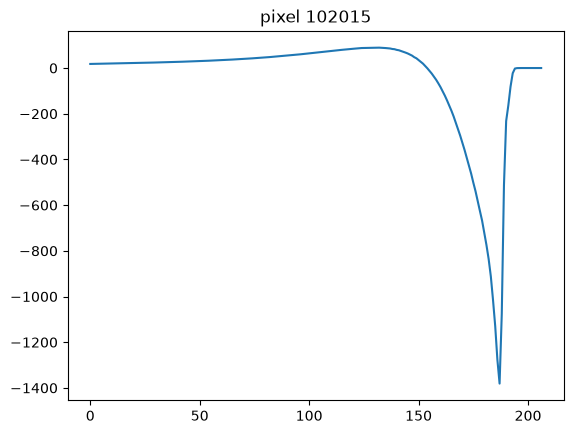

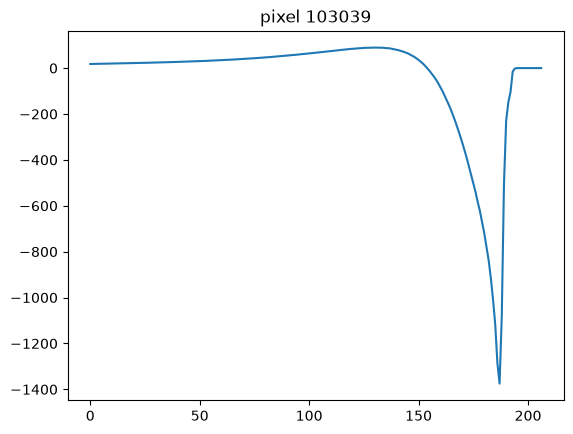

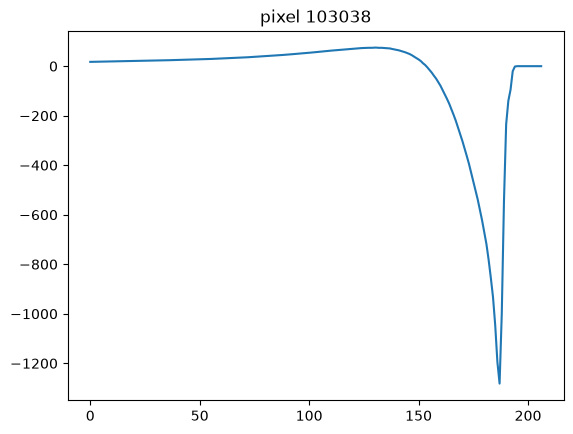

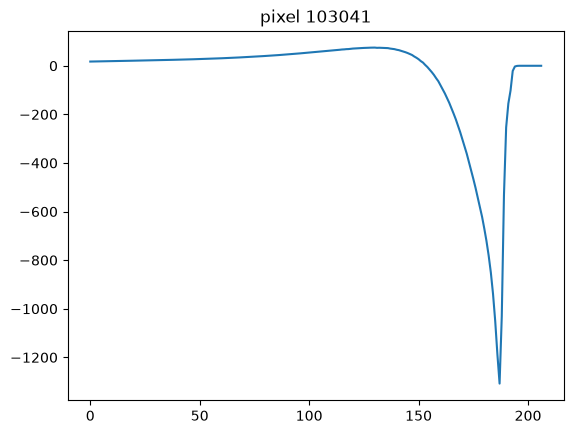

In [20]:
for i in order[:30]:
    plt.figure()
    plt.plot(s[i, :])
    plt.title(f"pixel {p[i]}")

In [21]:
!mkdir -p waveforms

In [87]:
def _dump_waveform(f, name, pixel_id=102527):
    signals, pixels = f['signals_near'], f['pixels_near']
    i = np.nonzero(pixels == pixel_id)[0][0]
    wvfm = signals[i, :]
    global w
    w = wvfm
    # end_tick is the index of the first padding value
    end_tick = max(np.nonzero(~np.isclose(wvfm, 0))[0]) + 1
    end_tick = min(end_tick, wvfm.shape[0] - 1)
    wvfm = wvfm[:end_tick + 1]
    if end_tick != wvfm.shape[0] - 1:
        assert wvfm[-1] == 0
    print(wvfm[-1])
    np.savetxt(f'waveforms/{name}.txt', wvfm, fmt='%.6f')

def dump_waveform(name, **kw):
    f = np.load(f'output/chg_inject/{name}.LARND.hdf5_signals/nf_signals.00.1.npz')
    _dump_waveform(f, name, **kw)

In [88]:
dump_waveform('parallel_mip')

0.0


In [89]:
def plot_dumped_waveform(name):
    arr = np.loadtxt(f'waveforms/{name}.txt')
    plt.plot(arr)
    global a
    a = arr

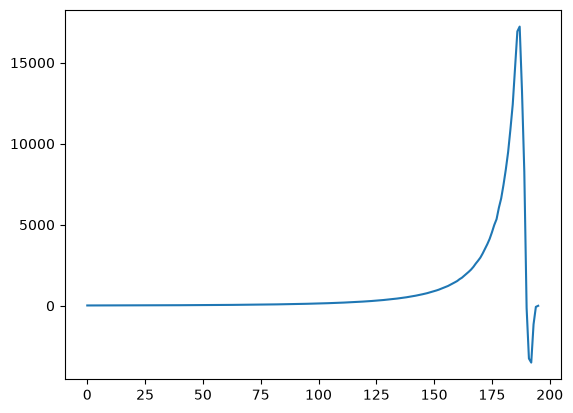

In [90]:
plot_dumped_waveform('parallel_mip')

In [91]:
f_sig_shower = np.load('/pscratch/sd/m/mkramer/test/larnd-sim.segFFE3/output/skim_more/prc16_r4_cutFix_saveSignals/showers.prc16_r4_cutFix_saveSignals.01.LARND.hdf5_signals/signals.14.npz')

In [92]:
_dump_waveform(f_sig_shower, 'shower', pixel_id=1145)

0.0


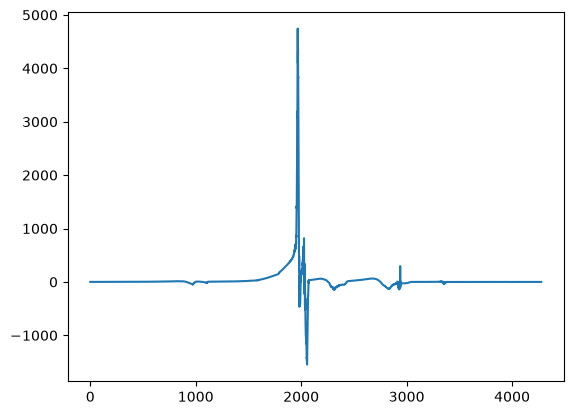

In [93]:
plot_dumped_waveform('shower')